In [1]:
%matplotlib inline

import random
import matplotlib.pyplot as plt
from copy import deepcopy
import numpy as np
import pystan 
import pandas as pd
import seaborn as sns
import math
import statistics as st
from matplotlib.backends.backend_pdf import PdfPages
import pickle
from tqdm.notebook import tqdm as tqdm

In [2]:
# Reduction data Import
datum = pd.read_csv('data/transportation/Static_Ecoli_growth_lettuce.csv')
pd.set_option('display.max_rows', None)
print(datum)

    TIME     N    N0  Temp
0      0  4.45  4.22     5
1     12  4.33  4.22     5
2     24  4.53  4.22     5
3     36  4.30  4.22     5
4     48  4.47  4.22     5
5     60  4.22  4.22     5
6     72  4.54  4.22     5
7     84  4.47  4.22     5
8     96  4.33  4.22     5
9    120  4.56  4.22     5
10     0  4.86  4.81    10
11    12  4.81  4.81    10
12    18  4.85  4.81    10
13    24  4.88  4.81    10
14    36  4.90  4.81    10
15    48  5.29  4.81    10
16    60  5.53  4.81    10
17    72  5.84  4.81    10
18    84  5.77  4.81    10
19    96  5.97  4.81    10
20   120  5.89  4.81    10
21     0  4.71  4.50    15
22     2  4.78  4.50    15
23     3  4.52  4.50    15
24     4  4.54  4.50    15
25     5  4.61  4.50    15
26     6  4.69  4.50    15
27     7  5.06  4.50    15
28     8  4.82  4.50    15
29     9  4.50  4.50    15
30    10  4.99  4.50    15
31    11  5.29  4.50    15
32    12  4.96  4.50    15
33    13  5.42  4.50    15
34    14  5.56  4.50    15
35    15  5.56  4.50    15
3

In [3]:
#counts
S = datum.iloc[:,1]

#Time
t = datum.iloc[:,0]

#temperature
Temp = datum.iloc[:,3]

#初期菌数
I0 = datum.iloc[:,2]

#個数N
N = len(S) 

In [4]:
#dataset作る

dat_Ecoli = {'N' : N, 't' : t, 'logC' : S, 'Temp' : Temp, 'logC0' : I0}

In [5]:
model = '''
data {
    int N;  // number of measurement cell
    real t[N];  // time
    real Temp[N];  // temperature
    real logC[N];  // measured cell
    real logC0[N]; // 10-log Initial number cell
}
transformed data{
    real lnC[N];  // measured cell
    real lnC0[N]; // natural log Initial number cell
    for (i in 1:N){
        lnC[i] = log(10)*logC[i];
        lnC0[i] = log(10)*logC0[i];
    }
}
parameters {
    real <lower = -2,upper = 2>  a;
    real <lower = 0,upper = 20> b;
    real <lower = 0,upper = 1>  c;
    real <lower = 0,upper = 5>  d;
    real <lower = 0> h0;
    real <lower = 0> sigma;   // measurement errors
}

transformed parameters{
    real alpha0;
    real <lower = 0,upper = 100> lnCmax[N];
    real mumax[N];
    real <lower = 0,upper = 100> lnC_mean[N];
    real lag[N];
    real A[N];
    
    alpha0  = exp(-h0);
    for (i in 1:N){
        lnCmax[i]  = a * Temp[i] + b ;
        mumax[i] = (c * (Temp[i]-d))^2;
        lag[i]   = (-log(alpha0))/mumax[i];
        A[i]     = t[i] + (1/mumax[i])*log(exp(-mumax[i]*t[i]) + exp(log(alpha0)) - exp(-mumax[i]*t[i]+log(alpha0)));
        lnC_mean[i]    = lnC0[i] + mumax[i]*A[i] - log(1 + (exp(mumax[i]*A[i])-1)/(exp(lnCmax[i]-lnC0[i]))); //Baranyi式
    }
}
    
model{
    sigma ~ cauchy(0, 0.5);
    for (i in 1:N){ 
        lnC[i] ~ normal(lnC_mean[i], sigma);
    }
}

'''

sm = pystan.StanModel(model_code=model)

with open('stan_model_growth_Ecoli.pkl', 'wb') as f:

    pickle.dump(sm, f)

INFO:pystan:COMPILING THE C++ CODE FOR MODEL anon_model_5fb1f5b3c8a231f0ef7ab2e44c15e07a NOW.
clang-12: warning: -Wl,-export_dynamic: 'linker' input unused [-Wunused-command-line-argument]
In file included from /var/folders/f9/2qbwnnt53m1dp3z2wqzblq540000gn/T/tmp9v92q8_j/stanfit4anon_model_5fb1f5b3c8a231f0ef7ab2e44c15e07a_2000147465819334421.cpp:836:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/numpy/core/include/numpy/arrayobject.h:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/numpy/core/include/numpy/ndarrayobject.h:12:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/numpy/core/include/numpy/ndarraytypes.h:1969:
/opt/anaconda3/envs/pystan/lib/python3.7/site-packages/numpy/core/include/numpy/npy_1_7_deprecated_api.h:17:2: warning: "Using deprecated NumPy API, disable it with "          "#define NPY_NO_DEPRECATED_API NPY_1_7_API_VERSION" [-W#warnings]
#warning "Using deprecated NumPy API, dis

  { return llt_inplace<typename MatrixType::Scalar, Lower>::blocked(m)==-1; }
                                                            ^
/opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/lib/eigen_3.3.3/Eigen/src/Cholesky/LLT.h:444:21: note: in instantiation of member function 'Eigen::internal::LLT_Traits<Eigen::Matrix<double, -1, -1, 0>, 1>::inplace_decomposition' requested here
  bool ok = Traits::inplace_decomposition(m_matrix);
                    ^
/opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/prim/mat/fun/cholesky_decompose.hpp:84:7: note: in instantiation of function template specialization 'Eigen::LLT<Eigen::Matrix<double, -1, -1, 0>, 1>::compute<Eigen::Matrix<double, -1, -1, 0>>' requested here
  llt.compute(m);
      ^
In file included from /var/folders/f9/2qbwnnt53m1dp3z2wqzblq540000gn/T/tmp9v92q8_j/stanfit4anon_model_5fb1f5b3c8a231f0ef7ab2e44c15e07a_2000147465819334421.cpp:846:
In file included f

In file included from /var/folders/f9/2qbwnnt53m1dp3z2wqzblq540000gn/T/tmp9v92q8_j/stanfit4anon_model_5fb1f5b3c8a231f0ef7ab2e44c15e07a_2000147465819334421.cpp:846:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan_fit.hpp:22:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/services/diagnose/diagnose.hpp:10:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/test_gradients.hpp:7:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/log_prob_grad.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/mat.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/core.hpp:5:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/s

In file included from /var/folders/f9/2qbwnnt53m1dp3z2wqzblq540000gn/T/tmp9v92q8_j/stanfit4anon_model_5fb1f5b3c8a231f0ef7ab2e44c15e07a_2000147465819334421.cpp:846:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan_fit.hpp:22:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/services/diagnose/diagnose.hpp:10:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/test_gradients.hpp:7:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/log_prob_grad.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/mat.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/core.hpp:5:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/s

In file included from /var/folders/f9/2qbwnnt53m1dp3z2wqzblq540000gn/T/tmp9v92q8_j/stanfit4anon_model_5fb1f5b3c8a231f0ef7ab2e44c15e07a_2000147465819334421.cpp:846:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan_fit.hpp:22:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/services/diagnose/diagnose.hpp:10:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/test_gradients.hpp:7:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/log_prob_grad.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/mat.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/core.hpp:5:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/s

In file included from /var/folders/f9/2qbwnnt53m1dp3z2wqzblq540000gn/T/tmp9v92q8_j/stanfit4anon_model_5fb1f5b3c8a231f0ef7ab2e44c15e07a_2000147465819334421.cpp:846:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan_fit.hpp:22:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/services/diagnose/diagnose.hpp:10:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/test_gradients.hpp:7:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/log_prob_grad.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/mat.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/core.hpp:5:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/s

In file included from /var/folders/f9/2qbwnnt53m1dp3z2wqzblq540000gn/T/tmp9v92q8_j/stanfit4anon_model_5fb1f5b3c8a231f0ef7ab2e44c15e07a_2000147465819334421.cpp:846:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan_fit.hpp:22:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/services/diagnose/diagnose.hpp:10:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/test_gradients.hpp:7:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/log_prob_grad.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/mat.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/core.hpp:5:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/s

In file included from /var/folders/f9/2qbwnnt53m1dp3z2wqzblq540000gn/T/tmp9v92q8_j/stanfit4anon_model_5fb1f5b3c8a231f0ef7ab2e44c15e07a_2000147465819334421.cpp:846:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan_fit.hpp:22:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/services/diagnose/diagnose.hpp:10:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/test_gradients.hpp:7:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/log_prob_grad.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/mat.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/core.hpp:5:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/s

In file included from /var/folders/f9/2qbwnnt53m1dp3z2wqzblq540000gn/T/tmp9v92q8_j/stanfit4anon_model_5fb1f5b3c8a231f0ef7ab2e44c15e07a_2000147465819334421.cpp:846:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan_fit.hpp:22:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/services/diagnose/diagnose.hpp:10:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/test_gradients.hpp:7:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/log_prob_grad.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/mat.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/core.hpp:5:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/s

In file included from /var/folders/f9/2qbwnnt53m1dp3z2wqzblq540000gn/T/tmp9v92q8_j/stanfit4anon_model_5fb1f5b3c8a231f0ef7ab2e44c15e07a_2000147465819334421.cpp:846:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan_fit.hpp:22:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/services/diagnose/diagnose.hpp:10:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/test_gradients.hpp:7:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/log_prob_grad.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/mat.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/core.hpp:5:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/s

148 warnings generated.
ld: warning: -pie being ignored. It is only used when linking a main executable


In [6]:
# Sampling Baysian model of gastric reduction
sm = pickle.load(open('stan_model_growth_Ecoli.pkl', 'rb'))
fit_Ecoli = sm.sampling(
    data = dat_Ecoli,
    iter = 25000+50000,
    chains = 4,
    warmup = 50000,
    thin = 10,
    seed = 1234
)

Rejecting initial value:
  Error evaluating the log probability at the initial value.
Exception: validate transformed params: lnC_mean[i_0__] is -inf, but must be greater than or equal to 0  (in 'unknown file name' at line 30)

Rejecting initial value:
  Error evaluating the log probability at the initial value.
Exception: validate transformed params: lnCmax[i_0__] is -0.984543, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

Rejecting initial value:
  Error evaluating the log probability at the initial value.
Exception: validate transformed params: lnCmax[i_0__] is -0.492115, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

Rejecting initial value:
  Error evaluating the log probability at the initial value.
Exception: validate transformed params: lnCmax[i_0__] is -3.2442, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

Rejecting initial value:
  Error evaluating the log probability at the initial va

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: validate transformed params: lnCmax[i_0__] is -9.96613, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: validate transformed params: lnCmax[i_0__] is -9.77347, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informat

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: validate transformed params: lnCmax[i_0__] is -0.0795363, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: validate transformed params: lnCmax[i_0__] is -1.58089, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Inform

Iteration:  7500 / 75000 [ 10%]  (Warmup)
Iteration:  7500 / 75000 [ 10%]  (Warmup)
Iteration:  7500 / 75000 [ 10%]  (Warmup)
Iteration:  7500 / 75000 [ 10%]  (Warmup)
Iteration: 15000 / 75000 [ 20%]  (Warmup)
Iteration: 15000 / 75000 [ 20%]  (Warmup)
Iteration: 15000 / 75000 [ 20%]  (Warmup)
Iteration: 15000 / 75000 [ 20%]  (Warmup)
Iteration: 22500 / 75000 [ 30%]  (Warmup)
Iteration: 22500 / 75000 [ 30%]  (Warmup)
Iteration: 22500 / 75000 [ 30%]  (Warmup)
Iteration: 22500 / 75000 [ 30%]  (Warmup)
Iteration: 30000 / 75000 [ 40%]  (Warmup)
Iteration: 30000 / 75000 [ 40%]  (Warmup)
Iteration: 30000 / 75000 [ 40%]  (Warmup)
Iteration: 30000 / 75000 [ 40%]  (Warmup)
Iteration: 37500 / 75000 [ 50%]  (Warmup)
Iteration: 37500 / 75000 [ 50%]  (Warmup)
Iteration: 37500 / 75000 [ 50%]  (Warmup)
Iteration: 37500 / 75000 [ 50%]  (Warmup)
Iteration: 45000 / 75000 [ 60%]  (Warmup)
Iteration: 45000 / 75000 [ 60%]  (Warmup)
Iteration: 45000 / 75000 [ 60%]  (Warmup)
Iteration: 45000 / 75000 [ 60%]  (

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: validate transformed params: lnCmax[i_0__] is -2.70591, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.



Iteration: 50001 / 75000 [ 66%]  (Sampling)
Iteration: 50001 / 75000 [ 66%]  (Sampling)
Iteration: 50001 / 75000 [ 66%]  (Sampling)
Iteration: 50001 / 75000 [ 66%]  (Sampling)
Iteration: 57500 / 75000 [ 76%]  (Sampling)
Iteration: 57500 / 75000 [ 76%]  (Sampling)
Iteration: 57500 / 75000 [ 76%]  (Sampling)
Iteration: 57500 / 75000 [ 76%]  (Sampling)
Iteration: 65000 / 75000 [ 86%]  (Sampling)
Iteration: 65000 / 75000 [ 86%]  (Sampling)
Iteration: 65000 / 75000 [ 86%]  (Sampling)
Iteration: 65000 / 75000 [ 86%]  (Sampling)
Iteration: 72500 / 75000 [ 96%]  (Sampling)
Iteration: 72500 / 75000 [ 96%]  (Sampling)
Iteration: 72500 / 75000 [ 96%]  (Sampling)
Iteration: 75000 / 75000 [100%]  (Sampling)

 Elapsed Time: 60.111 seconds (Warm-up)
               34.4495 seconds (Sampling)
               94.5605 seconds (Total)

Iteration: 75000 / 75000 [100%]  (Sampling)

 Elapsed Time: 60.265 seconds (Warm-up)
               35.425 seconds (Sampling)
               95.69 seconds (Total)

Iteration

In [7]:
print(fit_Ecoli)

Inference for Stan model: anon_model_5fb1f5b3c8a231f0ef7ab2e44c15e07a.
4 chains, each with iter=75000; warmup=50000; thin=10; 
post-warmup draws per chain=2500, total post-warmup draws=10000.

               mean se_mean     sd   2.5%    25%    50%    75%  97.5%  n_eff   Rhat
a              0.14  2.8e-4   0.03   0.08   0.12   0.14   0.16   0.19   9843    1.0
b             12.31  6.0e-3    0.6  11.27   11.9  12.27  12.66  13.62   9809    1.0
c              0.03  2.1e-5 2.1e-3   0.03   0.03   0.03   0.03   0.04   9890    1.0
d              2.16  7.5e-3   0.75   0.76   1.64   2.14   2.65    3.7   9848    1.0
h0             1.09  4.7e-3   0.46   0.23   0.77   1.08    1.4   2.04   9728    1.0
sigma          0.59  5.0e-4   0.05    0.5   0.56   0.59   0.62    0.7   9714    1.0
alpha0         0.37  1.7e-3   0.17   0.13   0.25   0.34   0.46   0.79   9834    1.0
lnCmax[1]      13.0  4.7e-3   0.46  12.19  12.68  12.96  13.26  14.01   9809    1.0
lnCmax[2]      13.0  4.7e-3   0.46  12.19  12.68  1

In [8]:
with open('fit_nuts_Ecoli_growth.pkl', 'wb') as g:

    pickle.dump(fit_Ecoli, g)

/opt/anaconda3/envs/pystan/lib/python3.7/site-packages/ipykernel_launcher.py:3: UserWarning: Pickling fit objects is an experimental feature!
The relevant StanModel instance must be pickled along with this fit object.
When unpickling the StanModel must be unpickled first.
  This is separate from the ipykernel package so we can avoid doing imports until


Progress:   0%|          | 0/110 [00:00<?, ?it/s]

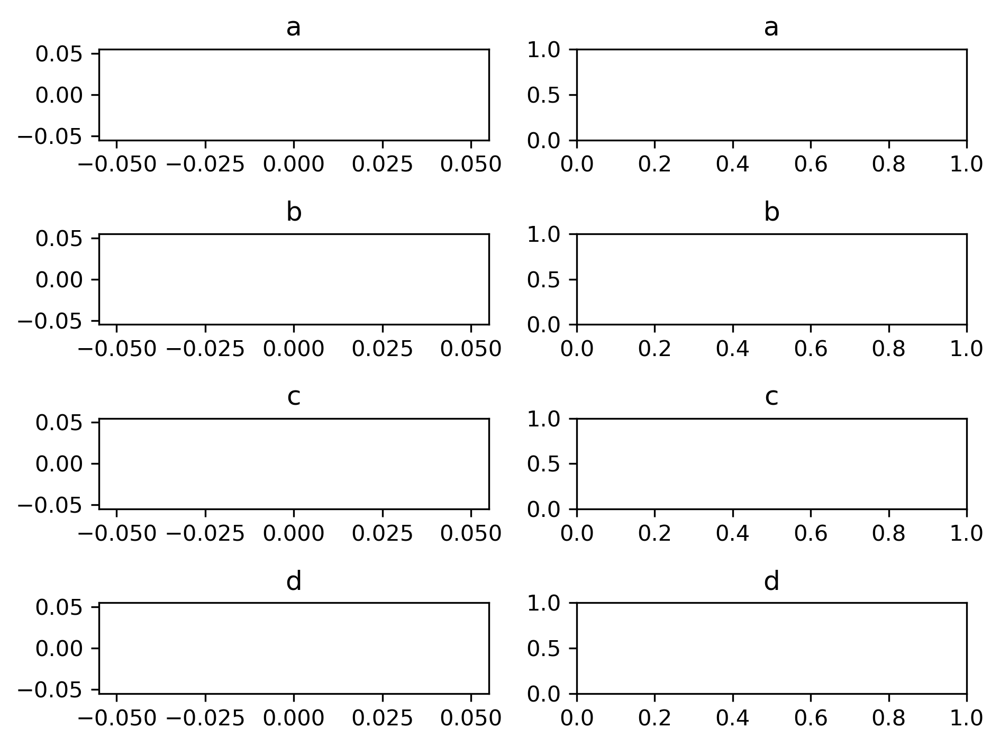

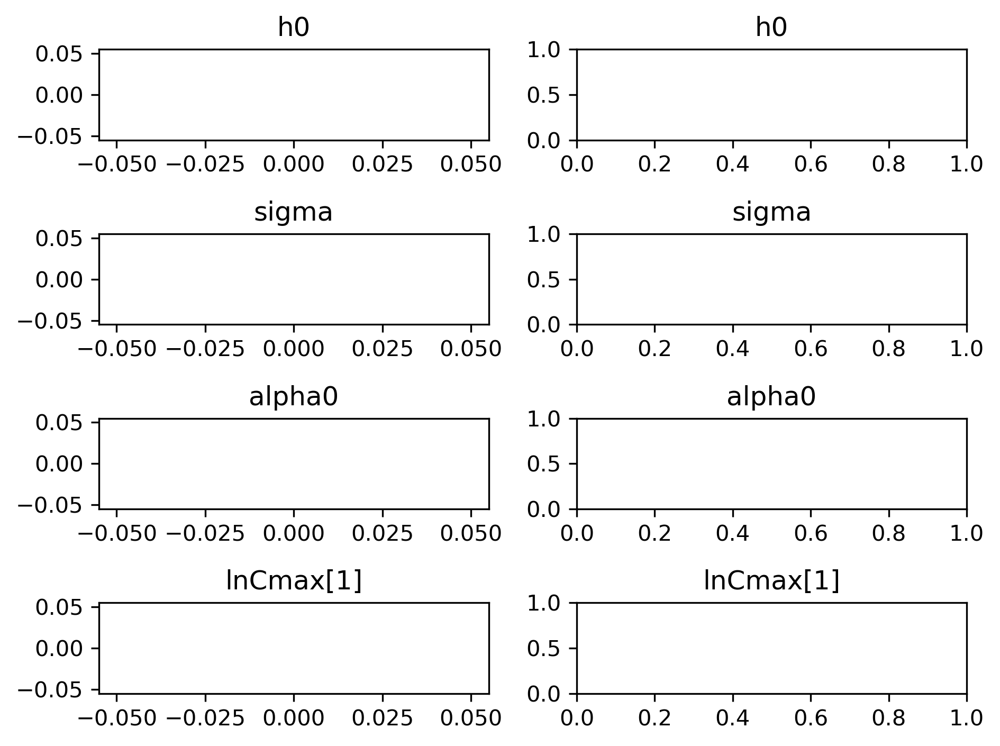

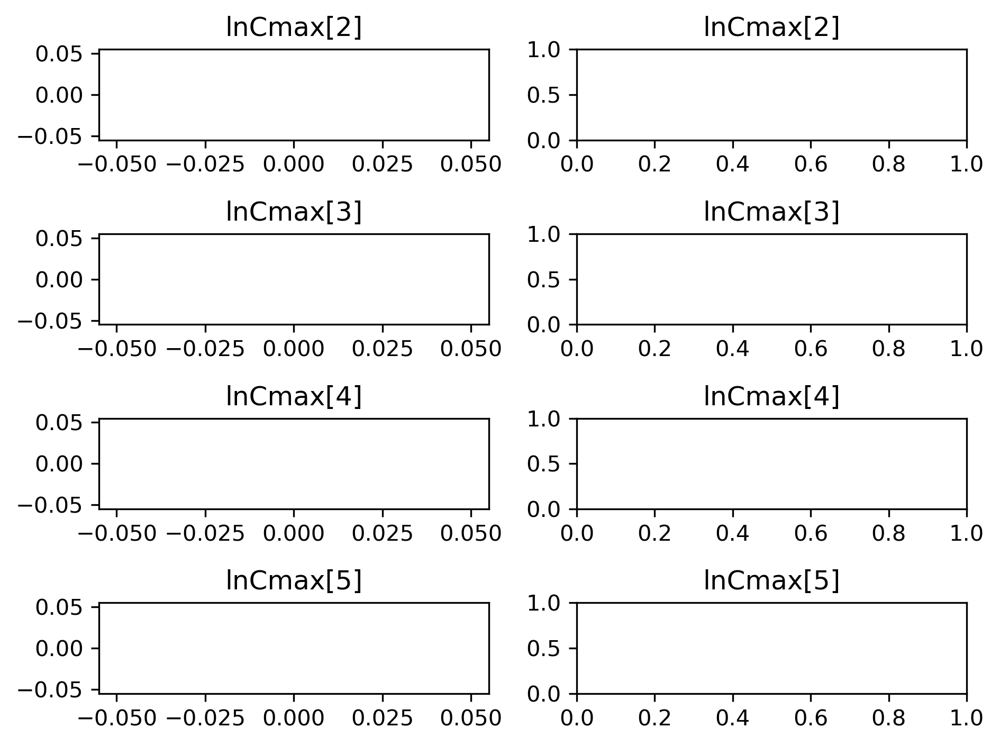

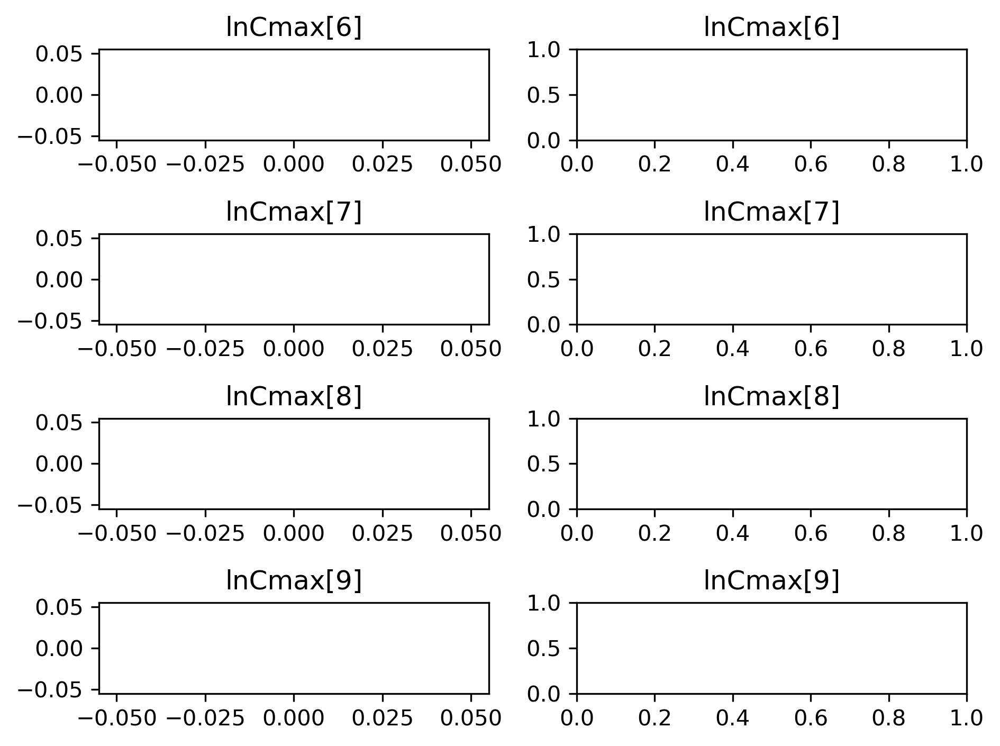

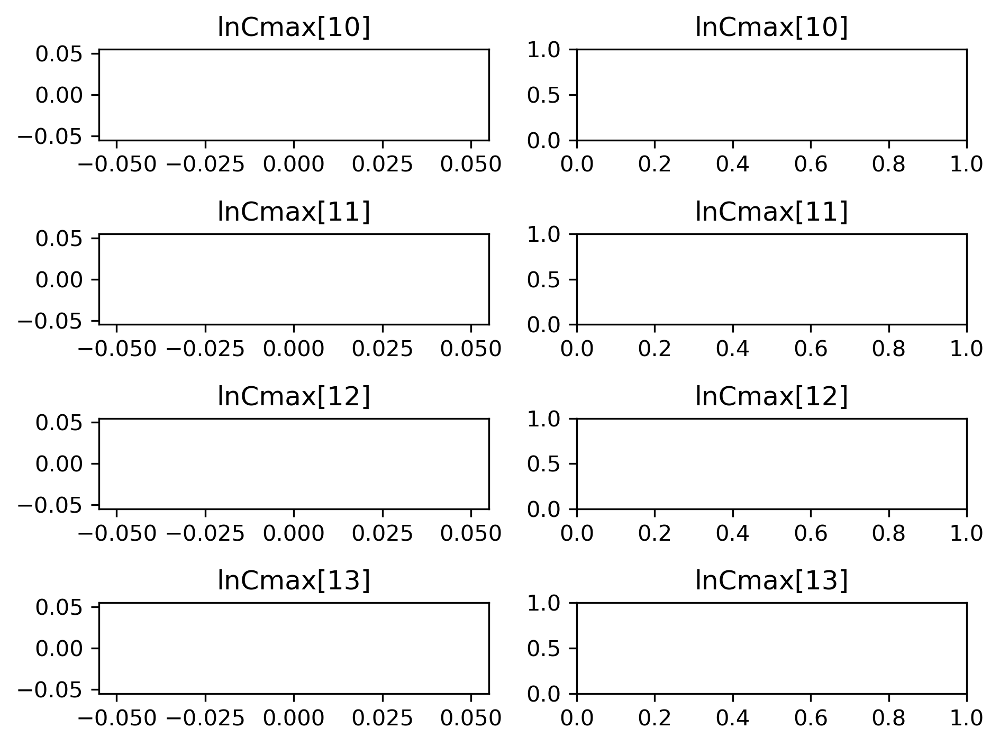

...

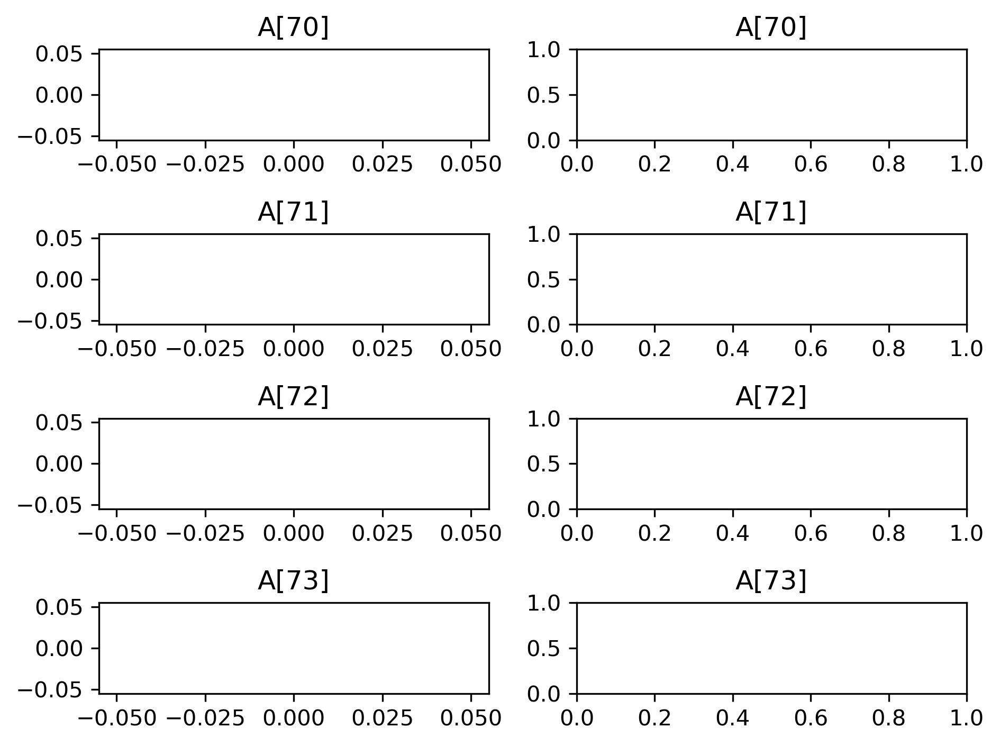

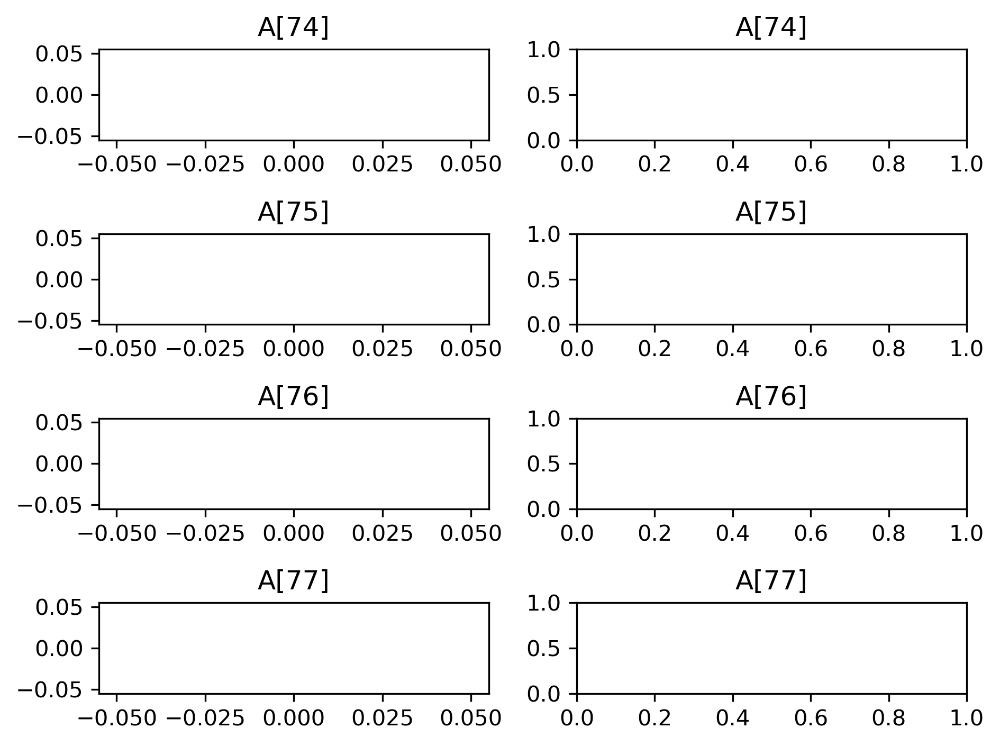

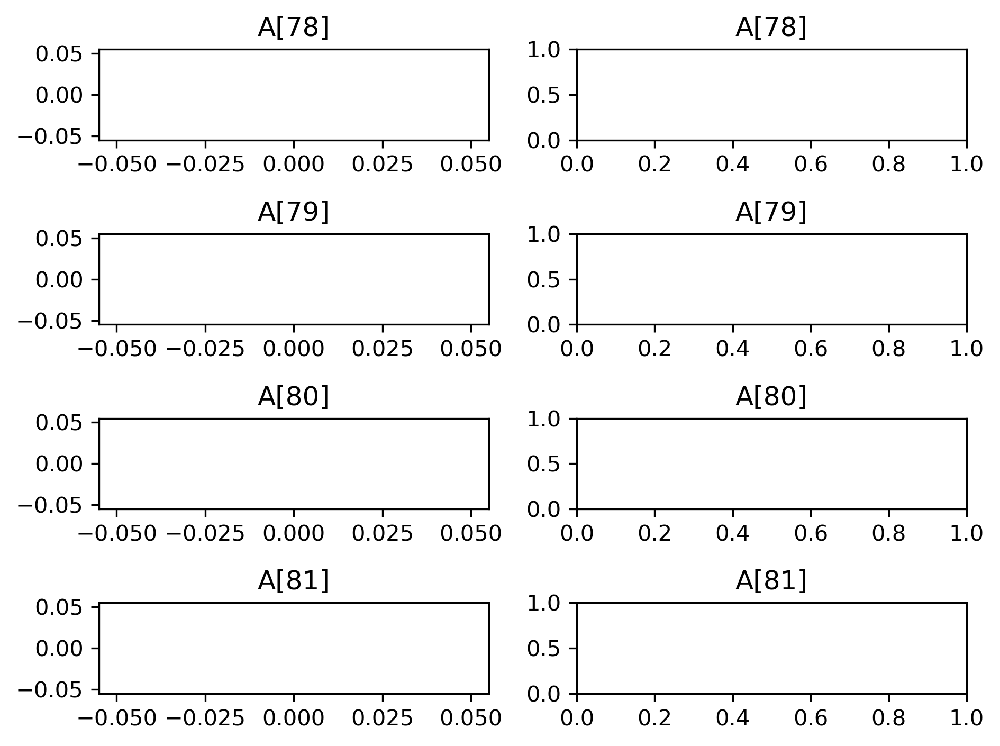

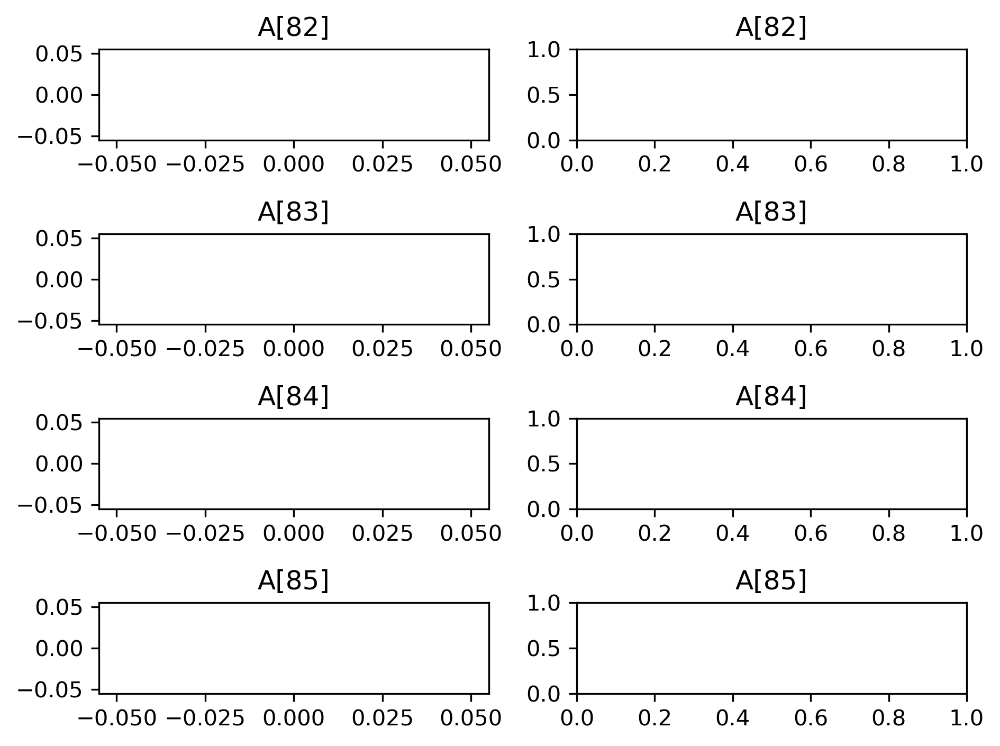

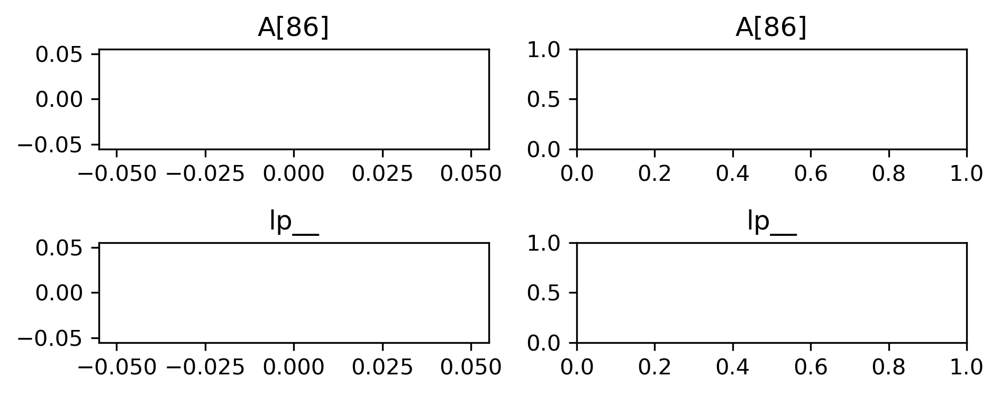

In [9]:
#計算過程を追跡する
samples = fit_Ecoli.extract(permuted = False, inc_warmup = True)
paraname = fit_Ecoli.sim["fnames_oi"]
palette = sns.color_palette()
ms = fit_Ecoli.extract(permuted=False, inc_warmup=True)
iter_from = fit_Ecoli.sim['warmup']
iter_range = np.arange(iter_from, ms.shape[0])
paraname = fit_Ecoli.sim['fnames_oi']
num_pages = math.ceil(len(paraname)/4)

#結果を何個表示するかを指定
for pg in tqdm(range(num_pages),desc='Progress', leave=False):
    plt.figure(dpi=300)
    for pos in range(4):
        pi = pg*4 + pos
        if pi >= len(paraname): break
        plt.subplot(4, 2, 2*pos+1)
        plt.tight_layout()
        [plt.plot(iter_range + 1, ms[iter_range,ci,pi], color=palette[ci]) for ci in range(ms.shape[1])]
        plt.title(paraname[pi])
        plt.subplot(4, 2, 2*(pos+1))
        plt.tight_layout()
        [sns.kdeplot(ms[iter_range,ci,pi], color=palette[ci]) for ci in range(ms.shape[1])]
        plt.title(paraname[pi])

    plt.show()

In [10]:
def Fit_Model(Temp, c, d) :
    return (c * (Temp - d))
samples = fit_Ecoli.extract(permuted=True)
temp_min = -5
temp_max = 30
devide = (temp_max-temp_min)*10
temp_interval = np.arange(temp_min, temp_max*(devide+1)/devide, 
                          (temp_max-temp_min)/devide, dtype="float")
Num_mcmc = len(samples["lp__"])
mu_conf_mcmc = np.zeros((len(temp_interval),Num_mcmc), dtype=float)
mu_conf_mcmc_quantile = np.zeros((len(temp_interval), 3), dtype=float)
mu_predict_mcmc = np.zeros((len(temp_interval),Num_mcmc), dtype=float)
mu_predict_mcmc_quantile = np.zeros((len(temp_interval), 3), dtype=float)
for j in tqdm(range(len(temp_interval)),desc='Progress', leave=False):
    for k in range(Num_mcmc):
        mu_conf_mcmc[j,k] = Fit_Model(temp_interval[j], samples["c"][k], samples["d"][k])

    mu_conf_mcmc_quantile[j,:] = np.quantile(mu_conf_mcmc[j,:],[0.025,  0.5, 0.975])

Progress:   0%|          | 0/351 [00:00<?, ?it/s]

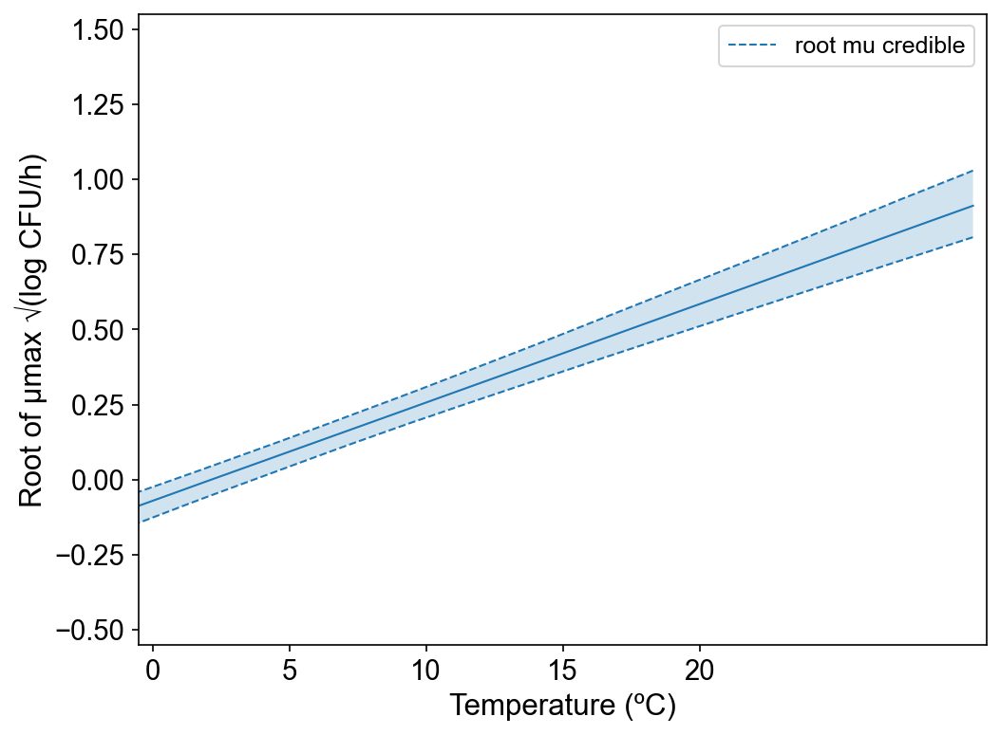

In [11]:
plt.figure(figsize=[6.4*1.2, 4.8*1.2], dpi=150)
plt.rcParams["font.family"] = "Arial"

plt.xticks(size=14)
plt.yticks(size=14)
plt.xlabel("Temperature (ºC)",size=15,fontname="Arial")
plt.ylabel("Root of µmax √(log CFU/h)",size=15,fontname="Arial")
plt.xticks(np.arange(-0, 21, 5))
plt.ylim([-0.55,1.55])
plt.xlim([-0.5,30.5])

Palette=sns.color_palette(n_colors = 3)
plt.fill_between(temp_interval, mu_conf_mcmc_quantile[:,0], mu_conf_mcmc_quantile[:,2], facecolor=Palette[0], alpha=0.2)
plt.plot(temp_interval, mu_conf_mcmc_quantile[:,0], lw=1, color=Palette[0], linestyle='--')
plt.plot(temp_interval, mu_conf_mcmc_quantile[:,2], lw=1, color=Palette[0], linestyle='--', label="root mu credible")
plt.plot(temp_interval, mu_conf_mcmc_quantile[:,1], lw=1, color=Palette[0])
plt.legend(fontsize=12)

plt.show()

In [12]:
# Reduction data Import   INTERNATIONAL JOURNAL OF FOOD MICROBIOLOGY 2010 Growth kinetics of Escherichia coli O157:H7 in mechanically-tenderized beef, Huang, Lihan
datum = pd.read_csv('data/transportation/Static_Ecoli_growth_beef.csv')
pd.set_option('display.max_rows', None)
print(datum)

          TIME         N        N0  Temp
0     0.000000  3.412158  3.412158     5
1    48.183556  3.052064  3.412158     5
2    71.845124  3.373966  3.412158     5
3   144.120459  3.174824  3.412158     5
4   168.212237  3.000233  3.412158     5
5   215.965583  2.814730  3.412158     5
6   311.902486  3.114808  3.412158     5
7   336.424474  2.601948  3.412158     5
8   359.655832  3.256663  3.412158     5
9   384.177820  3.488541  3.412158     5
10    0.000000  3.727555  3.727555    10
11   47.945205  3.654005  3.727555    10
12   71.232877  3.580336  3.727555    10
13  144.520548  4.368789  3.727555    10
14  167.808219  4.120733  3.727555    10
15  215.753425  4.798395  3.727555    10
16  312.328767  4.829040  3.727555    10
17  336.301370  4.289221  3.727555    10
18  359.589041  4.316162  3.727555    10
19  383.561644  4.225729  3.727555    10
20  600.684931  4.495059  3.727555    10
21    0.000000  3.631441  3.631441    15
22    3.961722  3.575999  3.631441    15
23    7.923445  

In [13]:
#counts
S = datum.iloc[:,1]

#Time
t = datum.iloc[:,0]

#temperature
Temp = datum.iloc[:,3]

#初期菌数
I0 = datum.iloc[:,2]

#個数N
N = len(S) 

In [14]:
#dataset作る

dat_Ecoli = {'N' : N, 't' : t, 'logC' : S, 'Temp' : Temp, 'logC0' : I0}

In [15]:
# Sampling Baysian model of gastric reduction
sm = pickle.load(open('stan_model_growth_Ecoli.pkl', 'rb'))
fit_Ecoli = sm.sampling(
    data = dat_Ecoli,
    iter = 25000+50000,
    chains = 4,
    warmup = 50000,
    thin = 10,
    seed = 1234
)

Rejecting initial value:
  Error evaluating the log probability at the initial value.
Exception: validate transformed params: lnCmax[i_0__] is -3.2442, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

Rejecting initial value:
  Error evaluating the log probability at the initial value.
Exception: validate transformed params: lnCmax[i_0__] is -0.492115, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

Rejecting initial value:
  Error evaluating the log probability at the initial value.
Exception: validate transformed params: lnC_mean[i_0__] is -inf, but must be greater than or equal to 0  (in 'unknown file name' at line 30)

Rejecting initial value:
  Error evaluating the log probability at the initial value.
Exception: validate transformed params: lnCmax[i_0__] is -2.84867, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

Rejecting initial value:
  Error evaluating the log probability at the initial val

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: validate transformed params: lnCmax[i_0__] is -9.99844, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: validate transformed params: lnCmax[i_0__] is -9.9895, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informati

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: validate transformed params: lnCmax[i_0__] is -0.432493, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: validate transformed params: lnCmax[i_0__] is -2.13795, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informa

Iteration:  7500 / 75000 [ 10%]  (Warmup)
Iteration:  7500 / 75000 [ 10%]  (Warmup)
Iteration:  7500 / 75000 [ 10%]  (Warmup)
Iteration:  7500 / 75000 [ 10%]  (Warmup)


Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: validate transformed params: lnCmax[i_0__] is -3.0772, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.



Iteration: 15000 / 75000 [ 20%]  (Warmup)
Iteration: 15000 / 75000 [ 20%]  (Warmup)
Iteration: 15000 / 75000 [ 20%]  (Warmup)
Iteration: 15000 / 75000 [ 20%]  (Warmup)
Iteration: 22500 / 75000 [ 30%]  (Warmup)
Iteration: 22500 / 75000 [ 30%]  (Warmup)
Iteration: 22500 / 75000 [ 30%]  (Warmup)
Iteration: 22500 / 75000 [ 30%]  (Warmup)
Iteration: 30000 / 75000 [ 40%]  (Warmup)
Iteration: 30000 / 75000 [ 40%]  (Warmup)
Iteration: 30000 / 75000 [ 40%]  (Warmup)
Iteration: 30000 / 75000 [ 40%]  (Warmup)


Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: validate transformed params: lnC_mean[i_0__] is -inf, but must be greater than or equal to 0  (in 'unknown file name' at line 30)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.



Iteration: 37500 / 75000 [ 50%]  (Warmup)
Iteration: 37500 / 75000 [ 50%]  (Warmup)
Iteration: 37500 / 75000 [ 50%]  (Warmup)
Iteration: 37500 / 75000 [ 50%]  (Warmup)
Iteration: 45000 / 75000 [ 60%]  (Warmup)
Iteration: 45000 / 75000 [ 60%]  (Warmup)
Iteration: 45000 / 75000 [ 60%]  (Warmup)
Iteration: 45000 / 75000 [ 60%]  (Warmup)
Iteration: 50001 / 75000 [ 66%]  (Sampling)
Iteration: 50001 / 75000 [ 66%]  (Sampling)
Iteration: 50001 / 75000 [ 66%]  (Sampling)


Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: validate transformed params: lnCmax[i_0__] is -0.825014, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: validate transformed params: lnCmax[i_0__] is -0.973352, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.



Iteration: 50001 / 75000 [ 66%]  (Sampling)
Iteration: 57500 / 75000 [ 76%]  (Sampling)
Iteration: 57500 / 75000 [ 76%]  (Sampling)
Iteration: 57500 / 75000 [ 76%]  (Sampling)
Iteration: 57500 / 75000 [ 76%]  (Sampling)
Iteration: 65000 / 75000 [ 86%]  (Sampling)
Iteration: 65000 / 75000 [ 86%]  (Sampling)
Iteration: 65000 / 75000 [ 86%]  (Sampling)
Iteration: 65000 / 75000 [ 86%]  (Sampling)
Iteration: 72500 / 75000 [ 96%]  (Sampling)
Iteration: 75000 / 75000 [100%]  (Sampling)

 Elapsed Time: 38.8027 seconds (Warm-up)
               20.3751 seconds (Sampling)
               59.1778 seconds (Total)

Iteration: 72500 / 75000 [ 96%]  (Sampling)
Iteration: 72500 / 75000 [ 96%]  (Sampling)
Iteration: 72500 / 75000 [ 96%]  (Sampling)
Iteration: 75000 / 75000 [100%]  (Sampling)

 Elapsed Time: 38.6758 seconds (Warm-up)
               27.3661 seconds (Sampling)
               66.0419 seconds (Total)

Iteration: 75000 / 75000 [100%]  (Sampling)

 Elapsed Time: 38.7297 seconds (Warm-up)
      

In [16]:
print(fit_Ecoli)

Inference for Stan model: anon_model_5fb1f5b3c8a231f0ef7ab2e44c15e07a.
4 chains, each with iter=75000; warmup=50000; thin=10; 
post-warmup draws per chain=2500, total post-warmup draws=10000.

               mean se_mean     sd   2.5%    25%    50%    75%  97.5%  n_eff   Rhat
a              0.23  4.3e-4   0.04   0.15    0.2   0.23   0.26   0.31   9373    1.0
b             10.87  9.7e-3   0.95   9.03  10.23  10.88  11.49  12.73   9538    1.0
c              0.04  3.4e-5 3.4e-3   0.03   0.04   0.04   0.04   0.05   9833    1.0
d              4.03  6.2e-3   0.61   2.74   3.61   4.09   4.51   4.94   9655    1.0
h0             2.07    0.01   1.17   0.27   1.23   1.92   2.73   4.76   9878    1.0
sigma          1.95  1.6e-3   0.17   1.65   1.83   1.93   2.05    2.3  10180    1.0
alpha0         0.21  2.1e-3    0.2 8.6e-3   0.07   0.15   0.29   0.76   8991    1.0
lnCmax[1]     12.02  7.9e-3   0.77  10.53   11.5  12.02  12.51  13.53   9545    1.0
lnCmax[2]     12.02  7.9e-3   0.77  10.53   11.5  1

In [17]:
with open('fit_nuts_Ecoli_growth_beef.pkl', 'wb') as g:

    pickle.dump(fit_Ecoli, g)

/opt/anaconda3/envs/pystan/lib/python3.7/site-packages/ipykernel_launcher.py:3: UserWarning: Pickling fit objects is an experimental feature!
The relevant StanModel instance must be pickled along with this fit object.
When unpickling the StanModel must be unpickled first.
  This is separate from the ipykernel package so we can avoid doing imports until


Progress:   0%|          | 0/94 [00:00<?, ?it/s]

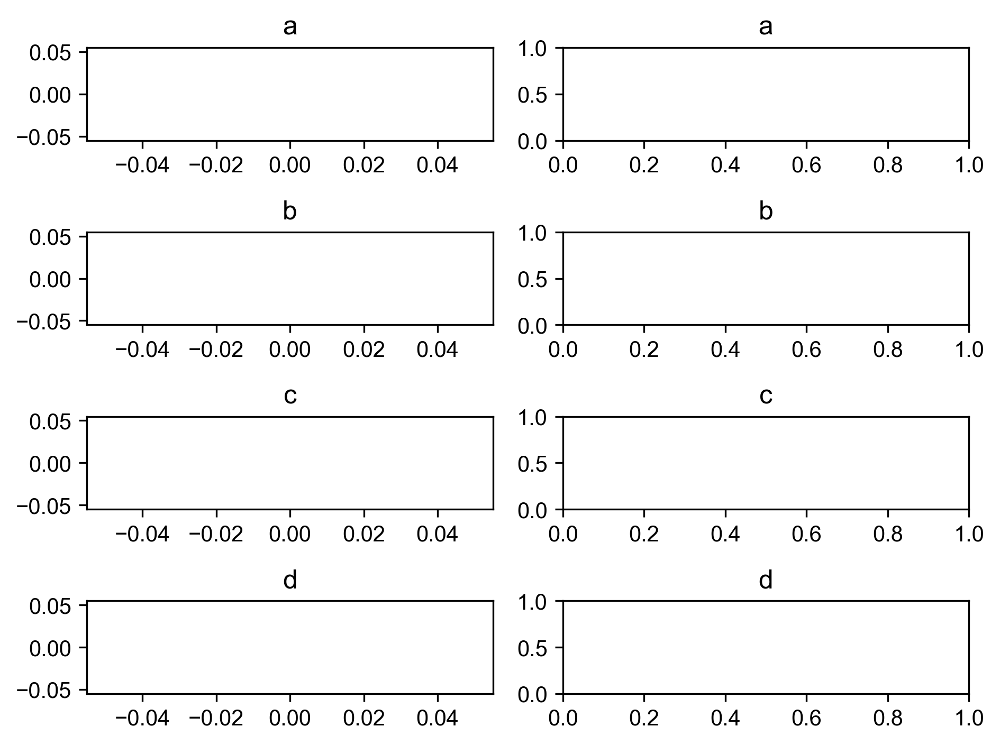

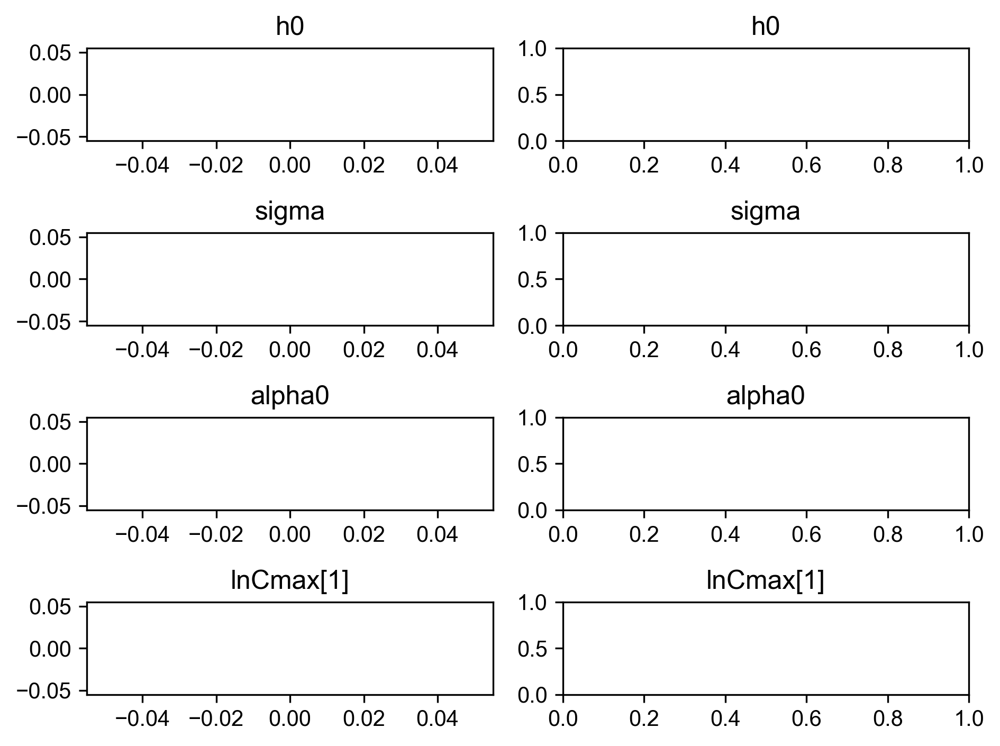

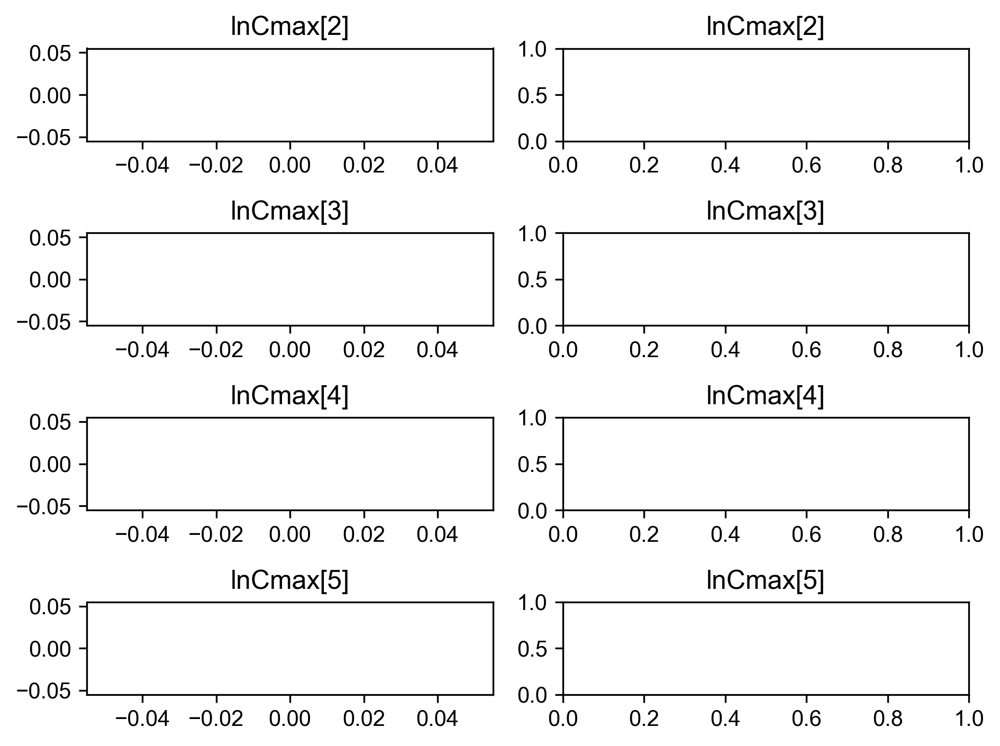

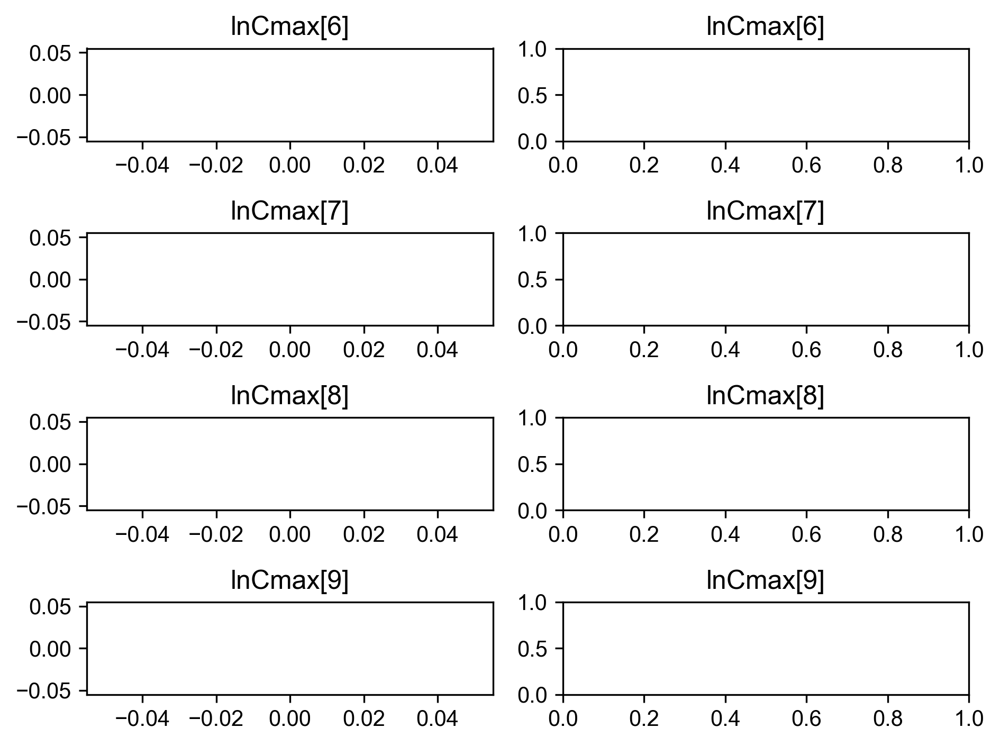

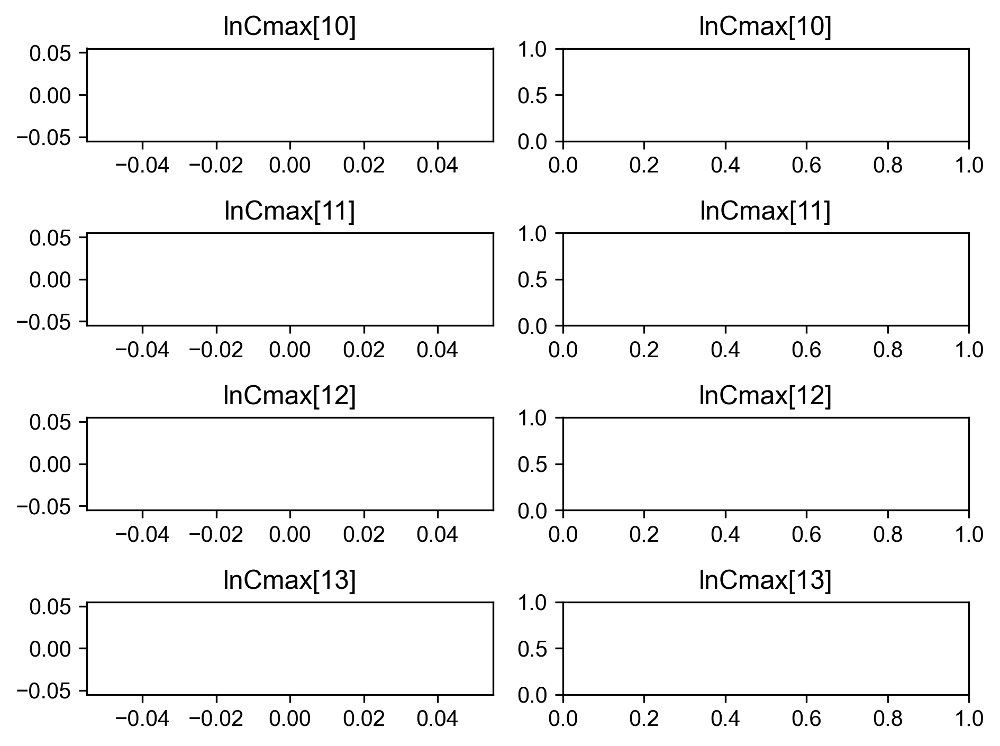

...

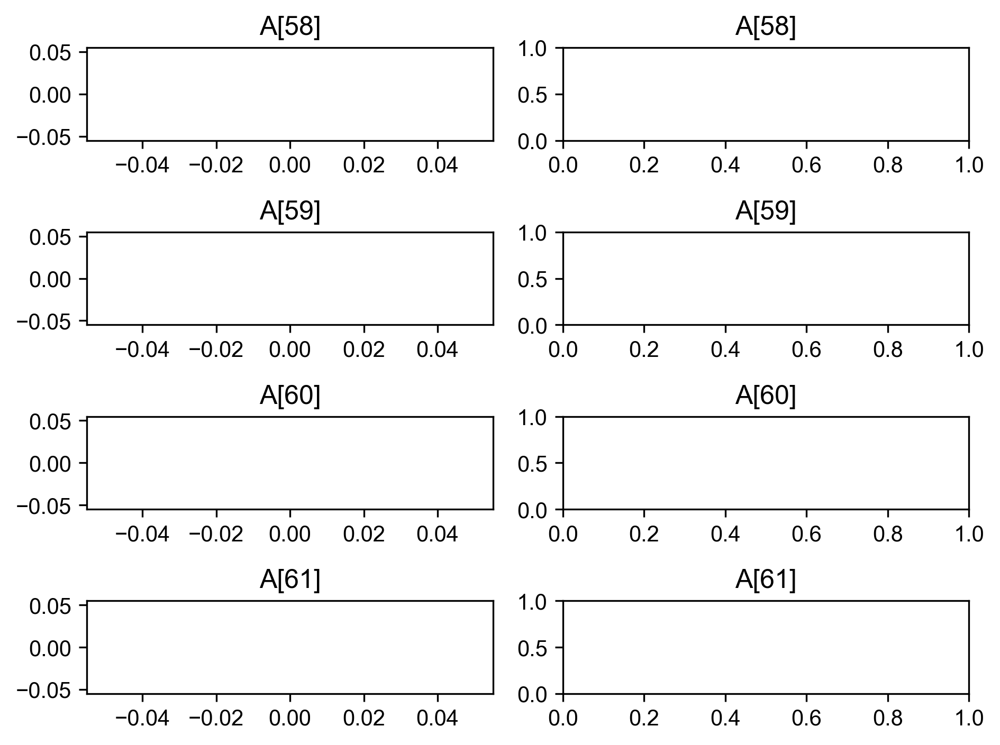

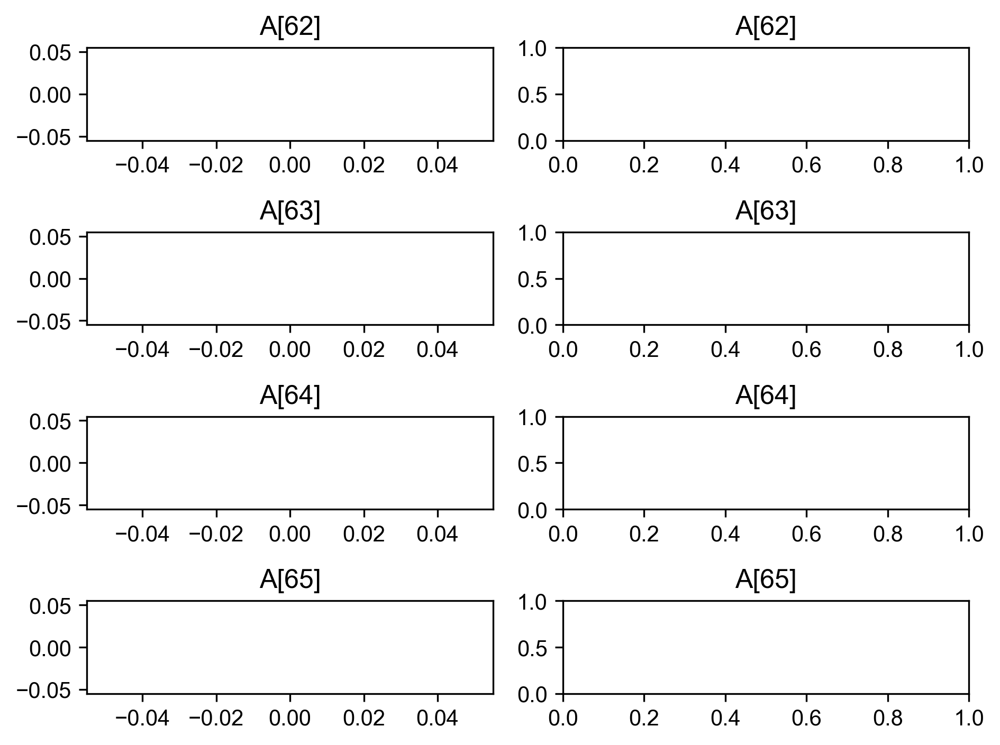

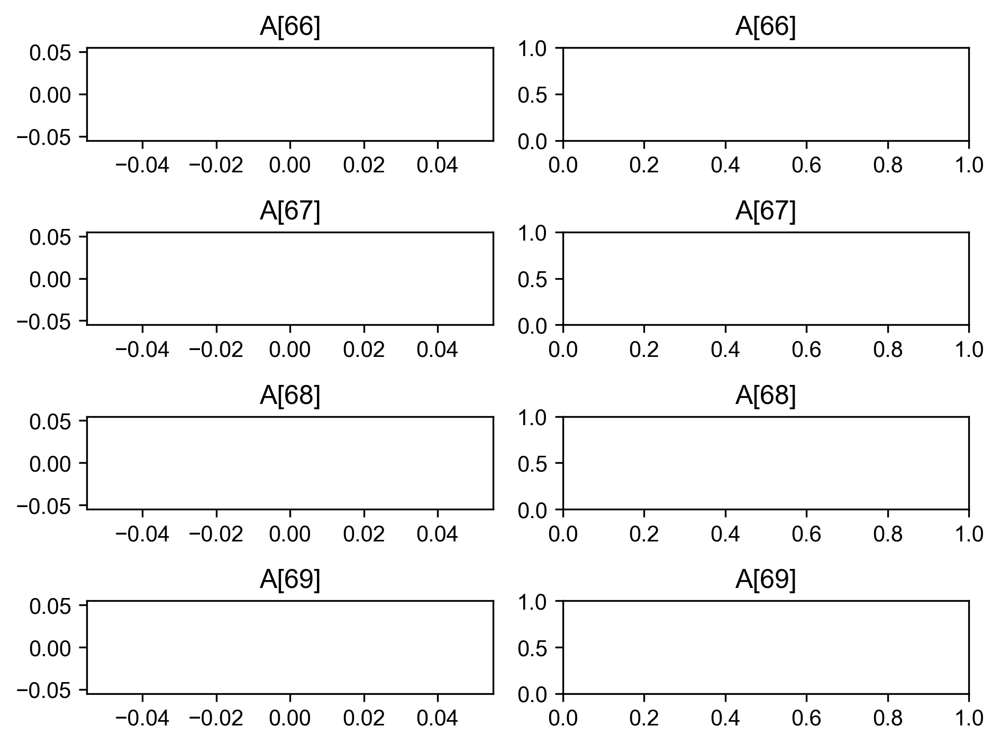

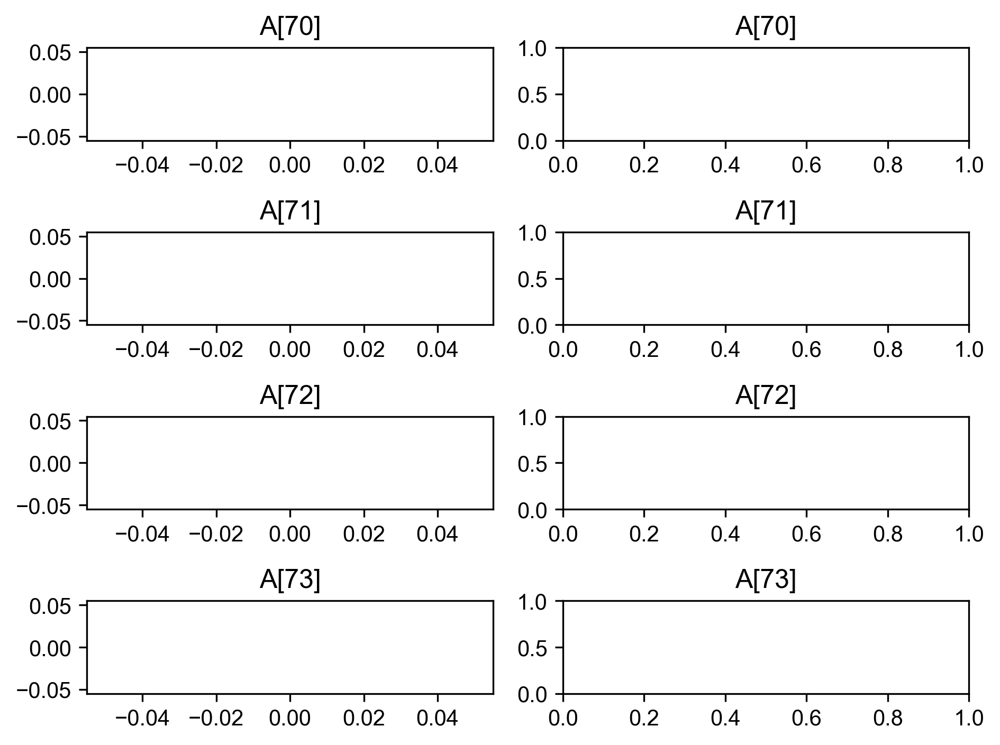

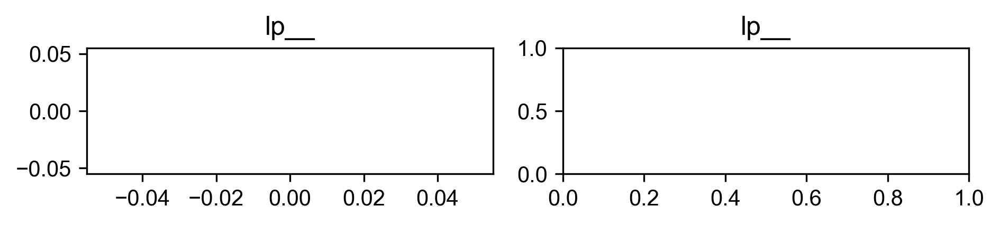

In [18]:
#計算過程を追跡する
samples = fit_Ecoli.extract(permuted = False, inc_warmup = True)
paraname = fit_Ecoli.sim["fnames_oi"]
palette = sns.color_palette()
ms = fit_Ecoli.extract(permuted=False, inc_warmup=True)
iter_from = fit_Ecoli.sim['warmup']
iter_range = np.arange(iter_from, ms.shape[0])
paraname = fit_Ecoli.sim['fnames_oi']
num_pages = math.ceil(len(paraname)/4)

#結果を何個表示するかを指定
for pg in tqdm(range(num_pages),desc='Progress', leave=False):
    plt.figure(dpi=300)
    for pos in range(4):
        pi = pg*4 + pos
        if pi >= len(paraname): break
        plt.subplot(4, 2, 2*pos+1)
        plt.tight_layout()
        [plt.plot(iter_range + 1, ms[iter_range,ci,pi], color=palette[ci]) for ci in range(ms.shape[1])]
        plt.title(paraname[pi])
        plt.subplot(4, 2, 2*(pos+1))
        plt.tight_layout()
        [sns.kdeplot(ms[iter_range,ci,pi], color=palette[ci]) for ci in range(ms.shape[1])]
        plt.title(paraname[pi])

    plt.show()